In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [37]:
image = cv2.imread('sar_1.jpg')
image_gray2 = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

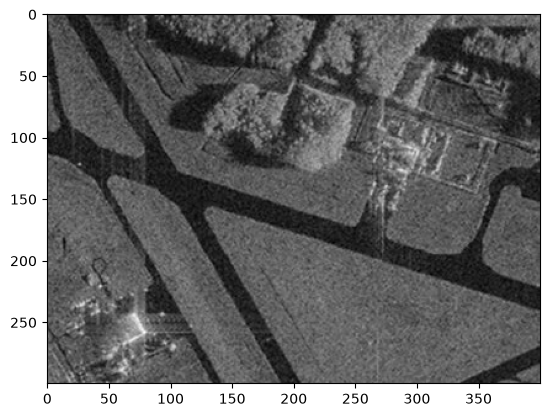

In [38]:
plt.imshow(image_gray2, cmap="gray")

# 1. Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [39]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [40]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask*255

In [47]:
seed_point = (250,250)
mask = region_growing(image_gray2,seed_point,homo_average,3, 25)

35
85
135
185
233
277
333
383
430
479
532
583
632
681
736
619
559
587
606
616
604
599
589
575
550
561
533
522
506
492
470
453
442
420
405
389
367
345
330
307
290
272
258
247
235
219
210
193
153
82
79
70
66
64
59
55
46
41
32
23
53
0


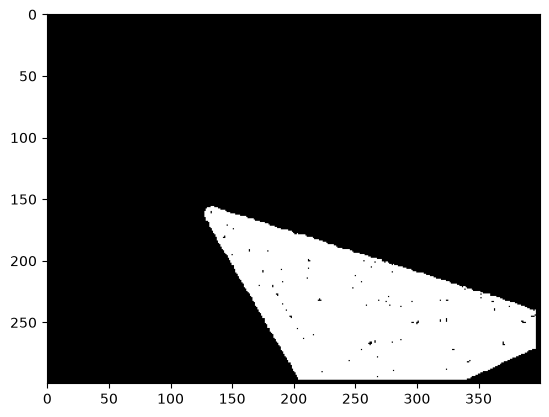

In [48]:
plt.imshow(mask, cmap="gray")

# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

In [1]:
# критерий однородности: яркость и текстура
# пиксель добавляется к области, если выполнены оба условия:
# 1. его яркость отличается от средней яркости области не более чем на T
# 2. локальное стандартное отклонение в окне 3x3 вокруг него не превышает T

def homo_bright_and_texture(img, mask, point, T):
    i, j = point
    
    # яркость
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    bright = abs(av_val - img[point]) <= T
    
    # текстура
    window = img[i-1:i+2, j-1:j+2].astype(float)
    tex = np.std(window) <= T
    
    return bright and tex

In [84]:
mask2 = region_growing(image_gray2, seed_point, homo_bright_and_texture, 3, 25)

35
85
135
185
233
277
333
383
430
479
532
583
632
681
736
619
559
587
606
615
604
599
589
575
550
560
533
522
506
491
469
452
442
418
403
386
367
345
330
307
290
270
258
247
235
219
210
193
153
81
79
70
66
64
59
55
46
41
32
23
15
35
0


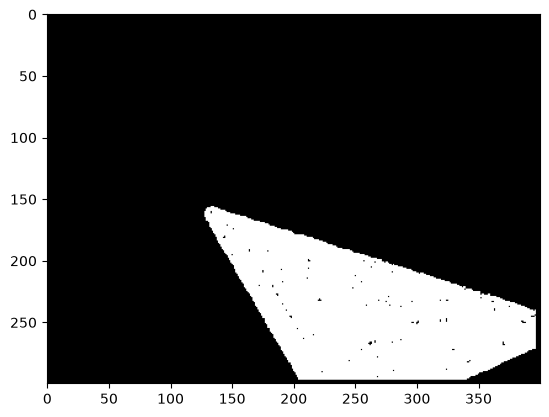

In [82]:
plt.imshow(mask2, cmap="gray")

In [91]:
from skimage.metrics import structural_similarity, mean_squared_error

# сравнение homo_average и homo_bright_and_texture
mse = mean_squared_error(mask, mask2)
(ssim, diff) = structural_similarity(mask, mask2, full=True)
print('mse: ', mse,' ssim: ', ssim)

mse:  9.75375  ssim:  0.9991912137107954


Text(0.5, 1.0, 'различающихся пикселей: 18')

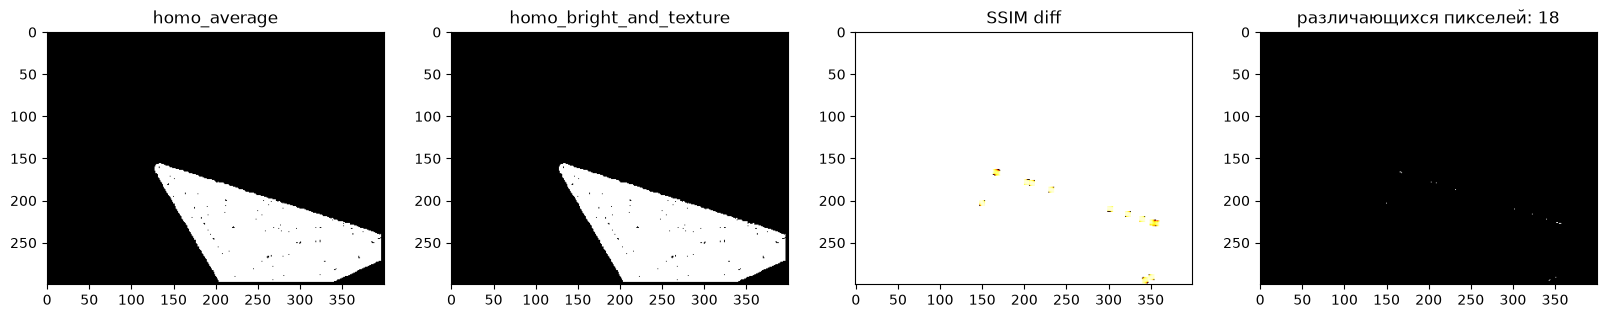

In [98]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(mask, cmap='gray')
axes[0].set_title('homo_average')

axes[1].imshow(mask2, cmap='gray')
axes[1].set_title('homo_bright_and_texture')

axes[2].imshow(diff, cmap='hot')
axes[2].set_title('SSIM diff')

difference = np.logical_xor(mask > 0, mask2 > 0)
axes[3].imshow(difference, cmap='gray')
axes[3].set_title(f'различающихся пикселей: {difference.sum()}')

Сравнение показало, что при одинаковых порогах маски практически совпадают
Текстура мало влияет на результат в данном примере, но она выполняет роль страховки выхода за пределы газона при ослаблении яркостного порога

# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [5]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

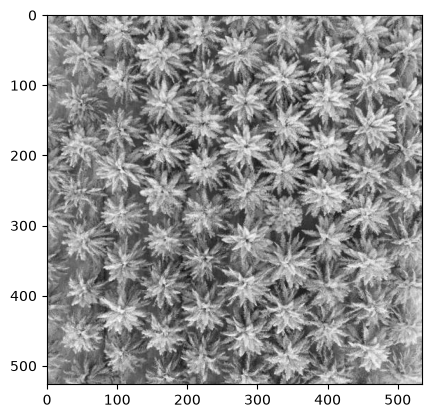

In [6]:
plt.imshow(image_gray, cmap="gray")

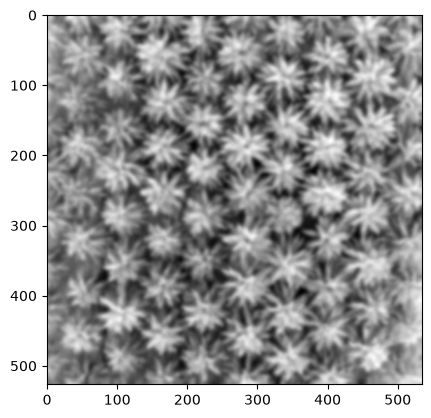

In [7]:
blurred = cv2.GaussianBlur(image_gray, (15, 15), 0)

plt.imshow(blurred, cmap="gray")

In [8]:
ret, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

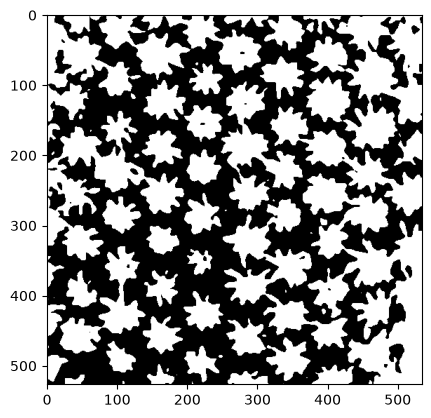

In [9]:
plt.imshow(thresh, cmap="gray")

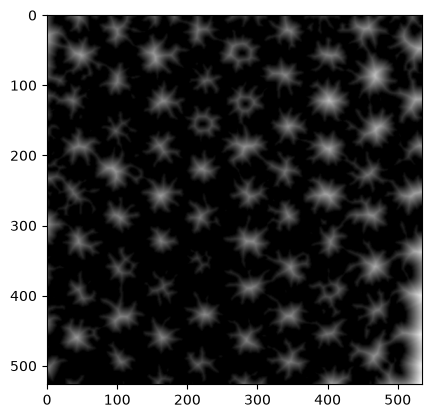

In [13]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
plt.imshow(dist, cmap="gray")

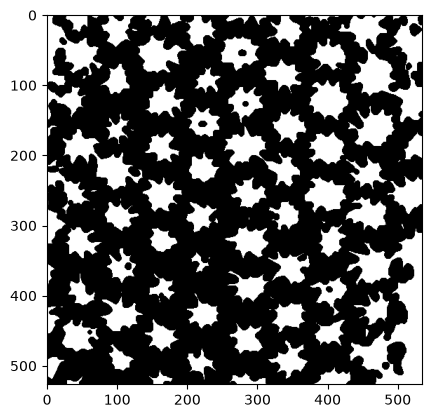

In [14]:
ret, sure_fg = cv2.threshold(dist, 0.1 * dist.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg, cmap="gray")

In [15]:
sure_fg = sure_fg.astype(np.uint8)

In [16]:
ret, markers = cv2.connectedComponents(sure_fg)

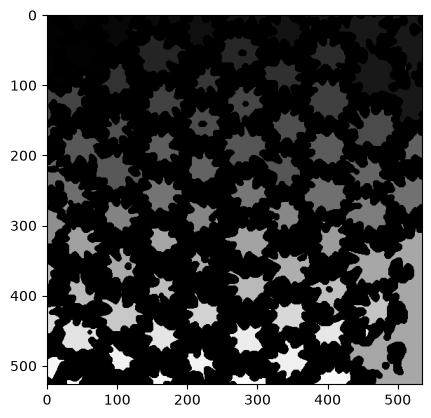

In [17]:
plt.imshow(markers, cmap="gray")

In [18]:
markers = cv2.watershed(image, markers)

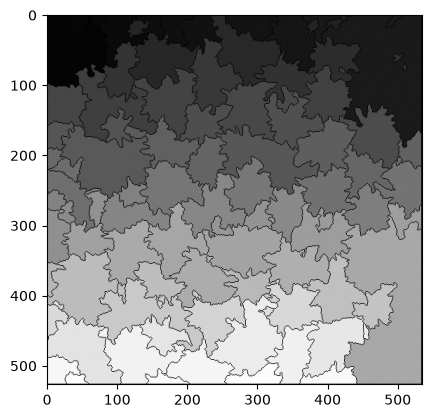

In [19]:
plt.imshow(markers, cmap="gray")

In [20]:
print("Nearly ~", len(np.unique(markers)), "palms")

Nearly ~ 117 palms
